In [1]:
!pip install -q mediapipe kagglehub scikit-learn pandas matplotlib seaborn gradio

import os, glob, shutil, pathlib
import cv2
import numpy as np
import pandas as pd
import kagglehub
import mediapipe as mp
from tqdm import tqdm
import urllib.request

# Unduh model file MediaPipe Hand Landmarker
model_url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
model_path = "hand_landmarker.task"
if not os.path.exists(model_path):
    print("Mengunduh model hand_landmarker.task...")
    urllib.request.urlretrieve(model_url, model_path)

# Unduh 2 dataset
path_achmad = kagglehub.dataset_download("achmadnoer/alfabet-bisindo")
path_agung = kagglehub.dataset_download("agungmrf/indonesian-sign-language-bisindo")

print("Model terunduh:", os.path.exists(model_path))
print("Dataset Achmad:", path_achmad)
print("Dataset Agung:", path_agung)

Using Colab cache for faster access to the 'alfabet-bisindo' dataset.


100%|██████████| 1.36G/1.36G [00:27<00:00, 53.8MB/s]

Extracting files...


Model terunduh: True
Dataset Achmad: /kaggle/input/alfabet-bisindo
Dataset Agung: /root/.cache/kagglehub/datasets/agungmrf/indonesian-sign-language-bisindo/versions/1


In [2]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Kumpulkan semua gambar dataset
image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG')
data_records = []

for base_path, source_name in [(path_achmad, 'achmad'), (path_agung, 'agung')]:
    for ext in image_extensions:
        for img_path in glob.glob(os.path.join(base_path, '**', ext), recursive=True):
            parent_folder = os.path.basename(os.path.dirname(img_path)).upper()
            if len(parent_folder) == 1 and 'A' <= parent_folder <= 'Z':
                data_records.append({
                    'filepath': img_path,
                    'label': parent_folder,
                    'source': source_name
                })

manifest_df = pd.DataFrame(data_records)
print(f"Total gambar ditemukan: {len(manifest_df)} dari {manifest_df['label'].nunique()} kelas.")

# Inisialisasi HandLandmarker API Modern
base_options = python.BaseOptions(model_asset_path='hand_landmarker.task')
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    num_hands=2,
    min_hand_detection_confidence=0.5
)
detector = vision.HandLandmarker.create_from_options(options)

def extract_landmarks(image_path):
    # Baca gambar
    img = cv2.imread(image_path)
    if img is None:
        return None
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=img_rgb)
    detection_result = detector.detect(mp_image)

    if not detection_result.hand_landmarks:
        return None

    # Vektor 126 fitur (2 tangan x 21 titik x 3 koordinat x,y,z)
    landmarks = np.zeros(126, dtype=np.float32)
    for hand_idx, hand_lms in enumerate(detection_result.hand_landmarks[:2]):
        base_x = hand_lms[0].x
        base_y = hand_lms[0].y
        base_z = hand_lms[0].z

        start_idx = hand_idx * 63
        for i, lm in enumerate(hand_lms):
            landmarks[start_idx + i * 3]     = lm.x - base_x
            landmarks[start_idx + i * 3 + 1] = lm.y - base_y
            landmarks[start_idx + i * 3 + 2] = lm.z - base_z

    return landmarks

# Ekstraksi koordinat
X_data, y_data = [], []
for _, row in tqdm(manifest_df.iterrows(), total=len(manifest_df), desc="Ekstraksi Titik"):
    feat = extract_landmarks(row['filepath'])
    if feat is not None:
        X_data.append(feat)
        y_data.append(row['label'])

X_data = np.array(X_data, dtype=np.float32)
y_data = np.array(y_data)

# Simpan hasil ekstraksi ke file lokal
np.save("X_landmarks_clean.npy", X_data)
np.save("y_labels_clean.npy", y_data)
print(f"\nBerhasil mengekstrak {len(X_data)} sampel tangan bersih!")

Total gambar ditemukan: 11782 dari 26 kelas.


Ekstraksi Titik: 100%|██████████| 11782/11782 [09:21<00:00, 20.97it/s]


Berhasil mengekstrak 9351 sampel tangan bersih!


In [8]:
import os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

# 1. Muat Data Hasil Ekstraksi Sel 2 secara Otomatis
if 'X_clean' in locals() and 'y_clean' in locals():
    X_data, y_raw = X_clean.copy(), y_clean.copy()
elif os.path.exists('X_landmarks_clean.npy') and os.path.exists('y_labels_clean.npy'):
    X_data = np.load('X_landmarks_clean.npy')
    y_raw = np.load('y_labels_clean.npy')
elif 'X' in locals() and 'labels' in locals():
    X_data, y_raw = X.copy(), labels.copy()
else:
    raise ValueError("Data X dan label belum ditemukan! Pastikan Sel 2 sudah dijalankan.")

y_raw = np.array([str(lbl).upper() for lbl in y_raw])
print(f"Total sampel awal sebelum pembersihan: {X_data.shape[0]}")

# 2. Pembersihan & Pemisahan Tegas Huruf 1 Tangan vs 2 Tangan
HURUF_1_TANGAN = {'C', 'E', 'I', 'J', 'L', 'O', 'R', 'U', 'V', 'Z'}
HURUF_2_TANGAN = {'A', 'B', 'D', 'F', 'G', 'H', 'K', 'M', 'N', 'P', 'Q', 'S', 'T', 'W', 'X', 'Y'}

X_bersih = X_data.copy()
indeks_valid = []

for h in np.unique(y_raw):
    idx_kelas = np.where(y_raw == h)[0]

    if h in HURUF_1_TANGAN:
        # Paksa slot tangan ke-2 (indeks 63..125) menjadi 0 murni untuk huruf 1 tangan
        X_bersih[idx_kelas, 63:] = 0.0
        indeks_valid.extend(idx_kelas)

    elif h in HURUF_2_TANGAN:
        # Cek sampel mana yang tangan keduanya berhasil terdeteksi (tidak 0 semua)
        tangan_2_terbaca = np.any(X_bersih[idx_kelas, 63:] != 0, axis=1)
        idx_2_tangan = idx_kelas[tangan_2_terbaca]

        # Pengaman: Gunakan hasil filter jika sampel yang tersisa minimal 10 foto,
        # agar tidak ada abjad yang hilang saat training
        if len(idx_2_tangan) >= 10:
            indeks_valid.extend(idx_2_tangan)
        else:
            indeks_valid.extend(idx_kelas)
    else:
        indeks_valid.extend(idx_kelas)

indeks_valid = np.array(sorted(indeks_valid))
X_bersih = X_bersih[indeks_valid]
y_bersih = y_raw[indeks_valid]
print(f"Total sampel valid setelah filter 1 vs 2 tangan: {X_bersih.shape[0]}")

# 3. Encoding Label A-Z & Pembagian Train/Test (80:20)
le = LabelEncoder()
y_encoded = le.fit_transform(y_bersih)
num_classes = len(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X_bersih, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Fungsi bantu agar penambahan noise TIDAK mengotori slot tangan ke-2 yang bernilai 0
def tambah_noise_aman(data_x, level_noise):
    mask_aktif = (data_x != 0).astype(np.float32)
    noise = np.random.normal(0, level_noise, data_x.shape).astype(np.float32)
    return data_x + (noise * mask_aktif)

# 4. Augmentasi Koordinat Umum (Semua Huruf)
X_train_noise = tambah_noise_aman(X_train, 0.012)
X_train_scale_up = X_train * 1.06
X_train_scale_down = X_train * 0.94

# 5. Penajaman Ekstra Khusus Huruf Rawan Tertukar (C, D, G, J, M, N, R, S, U, Y)
huruf_fokus = ['C', 'D', 'G', 'J', 'M', 'N', 'R', 'S', 'U', 'Y']
idx_fokus = [np.where(le.classes_ == h)[0][0] for h in huruf_fokus if h in le.classes_]

mask_fokus = np.isin(y_train, idx_fokus)
X_fokus = X_train[mask_fokus]
y_fokus = y_train[mask_fokus]

X_fokus_1 = tambah_noise_aman(X_fokus, 0.008)
X_fokus_2 = tambah_noise_aman(X_fokus, 0.016)
X_fokus_3 = X_fokus * 1.04

# Gabungkan seluruh data latih
X_train_aug = np.concatenate([
    X_train, X_train_noise, X_train_scale_up, X_train_scale_down,
    X_fokus_1, X_fokus_2, X_fokus_3
], axis=0)

y_train_aug = np.concatenate([
    y_train, y_train, y_train, y_train,
    y_fokus, y_fokus, y_fokus
], axis=0)

# Acak urutan data training setelah digabung
urutan_acak = np.random.permutation(len(X_train_aug))
X_train_aug = X_train_aug[urutan_acak]
y_train_aug = y_train_aug[urutan_acak]

print(f"Total sampel training setelah augmentasi: {X_train_aug.shape[0]}")

# Hitung bobot kelas seimbang (Class Weights)
bobot_array = compute_class_weight('balanced', classes=np.unique(y_train_aug), y=y_train_aug)
class_weight_dict = {i: float(bobot_array[i]) for i in range(len(bobot_array))}

# 6. Bangun Arsitektur Model MLP Landmark (126 Input)
model_mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(126,)),

    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(num_classes, activation='softmax')
])

model_mlp.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 7. Callbacks & Proses Training
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'bisindo_mlp_landmark.keras', monitor='val_accuracy', save_best_only=True, verbose=0
    )
]

history = model_mlp.fit(
    X_train_aug, y_train_aug,
    validation_data=(X_test, y_test),
    epochs=80,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

# Simpan model terbaik
model_mlp.save('bisindo_mlp_landmark.keras')
print("\nTraining selesai! Model terbaik tersimpan di 'bisindo_mlp_landmark.keras'.")

Total sampel awal sebelum pembersihan: 9351
Total sampel valid setelah filter 1 vs 2 tangan: 7390
Total sampel training setelah augmentasi: 30269
Epoch 1/80
946/946 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7239 - loss: 1.0316 - val_accuracy: 0.9222 - val_loss: 0.2768 - learning_rate: 0.0010
Epoch 2/80
946/946 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.8822 - loss: 0.4161 - val_accuracy: 0.9425 - val_loss: 0.1856 - learning_rate: 0.0010
Epoch 3/80
946/946 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9121 - loss: 0.3107 - val_accuracy: 0.9574 - val_loss: 0.1311 - learning_rate: 0.0010
Epoch 4/80
946/946 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9254 - loss: 0.2551 - val_accuracy: 0.9635 - val_loss: 0.1336 - learning_rate: 0.0010
Epoch 5/80
946/946 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9332 - loss: 0.2215 - val_accuracy: 0.9513 - val_loss: 0.1614 - learning_rate: 0.0010
Epoch 6/80
946/946 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9384 - loss: 0.2092 - val_ac

Test Accuracy MLP Landmark: 0.9878 (98.78%)
Test Loss MLP Landmark    : 0.0594

Classification Report:

              precision    recall  f1-score   support

           A     0.9787    1.0000    0.9892        46
           B     0.9565    1.0000    0.9778        22
           C     1.0000    1.0000    1.0000        66
           D     0.9836    0.9677    0.9756        62
           E     1.0000    1.0000    1.0000        72
           F     0.8947    0.9444    0.9189        18
           G     1.0000    1.0000    1.0000        58
           H     1.0000    1.0000    1.0000        57
           I     1.0000    1.0000    1.0000        78
           J     1.0000    1.0000    1.0000        77
           K     0.9677    1.0000    0.9836        60
           L     0.9863    1.0000    0.9931        72
           M     0.9778    0.9778    0.9778        45
           N     0.9474    0.9474    0.9474        19
           O     1.0000    1.0000    1.0000        76
           P     0.9375    0.90

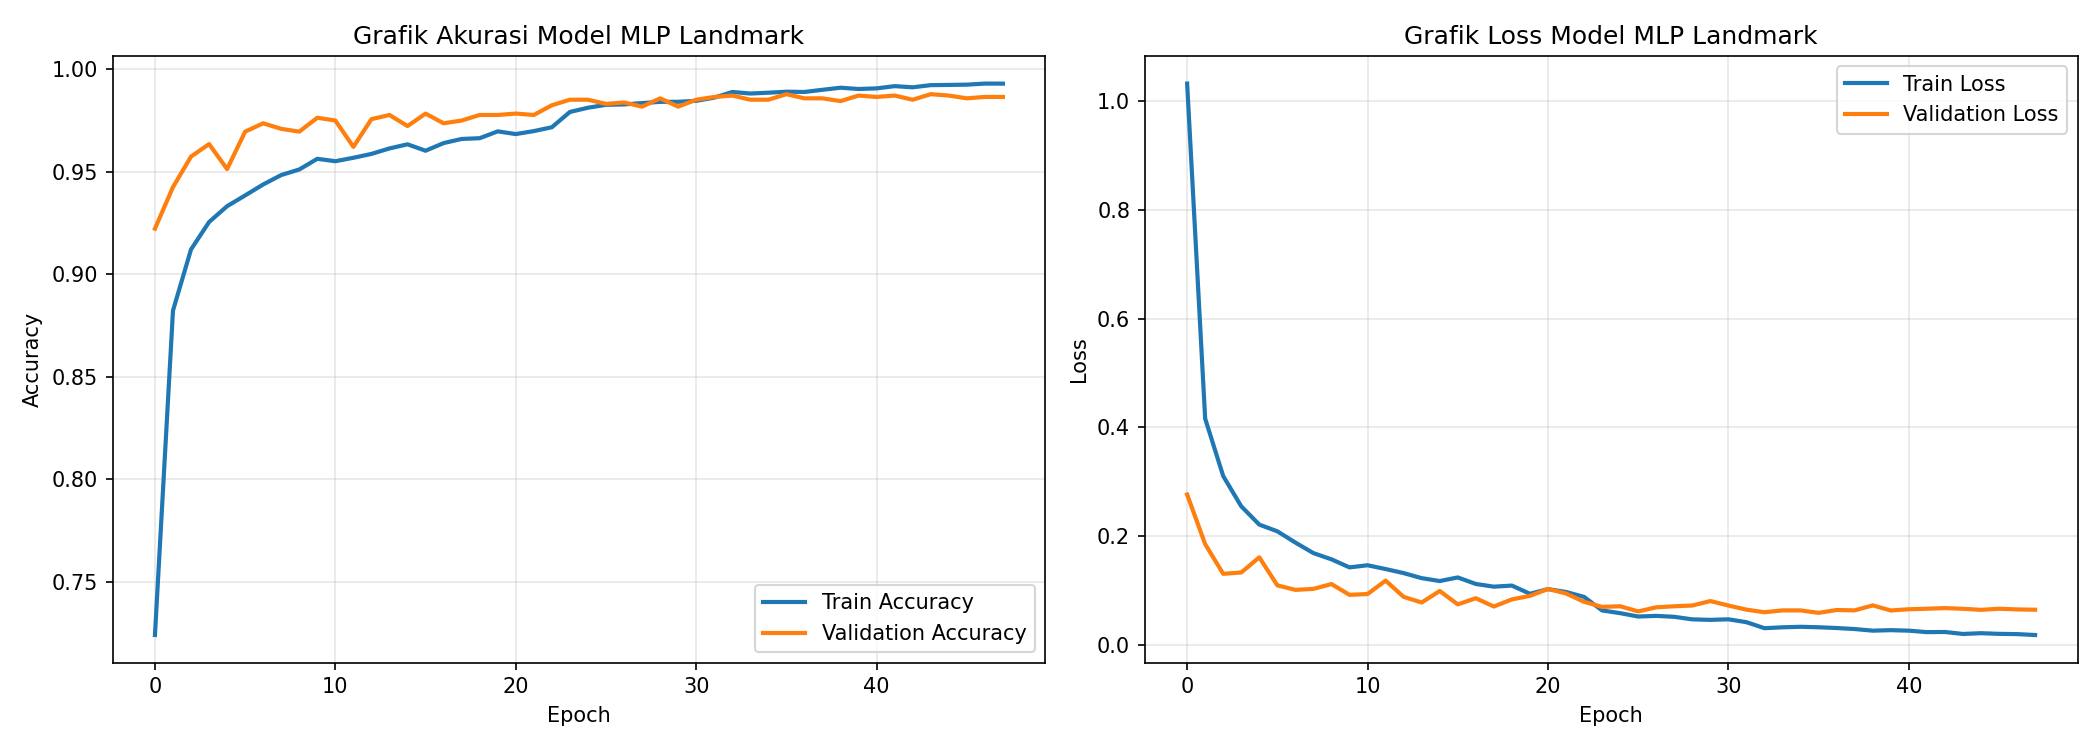

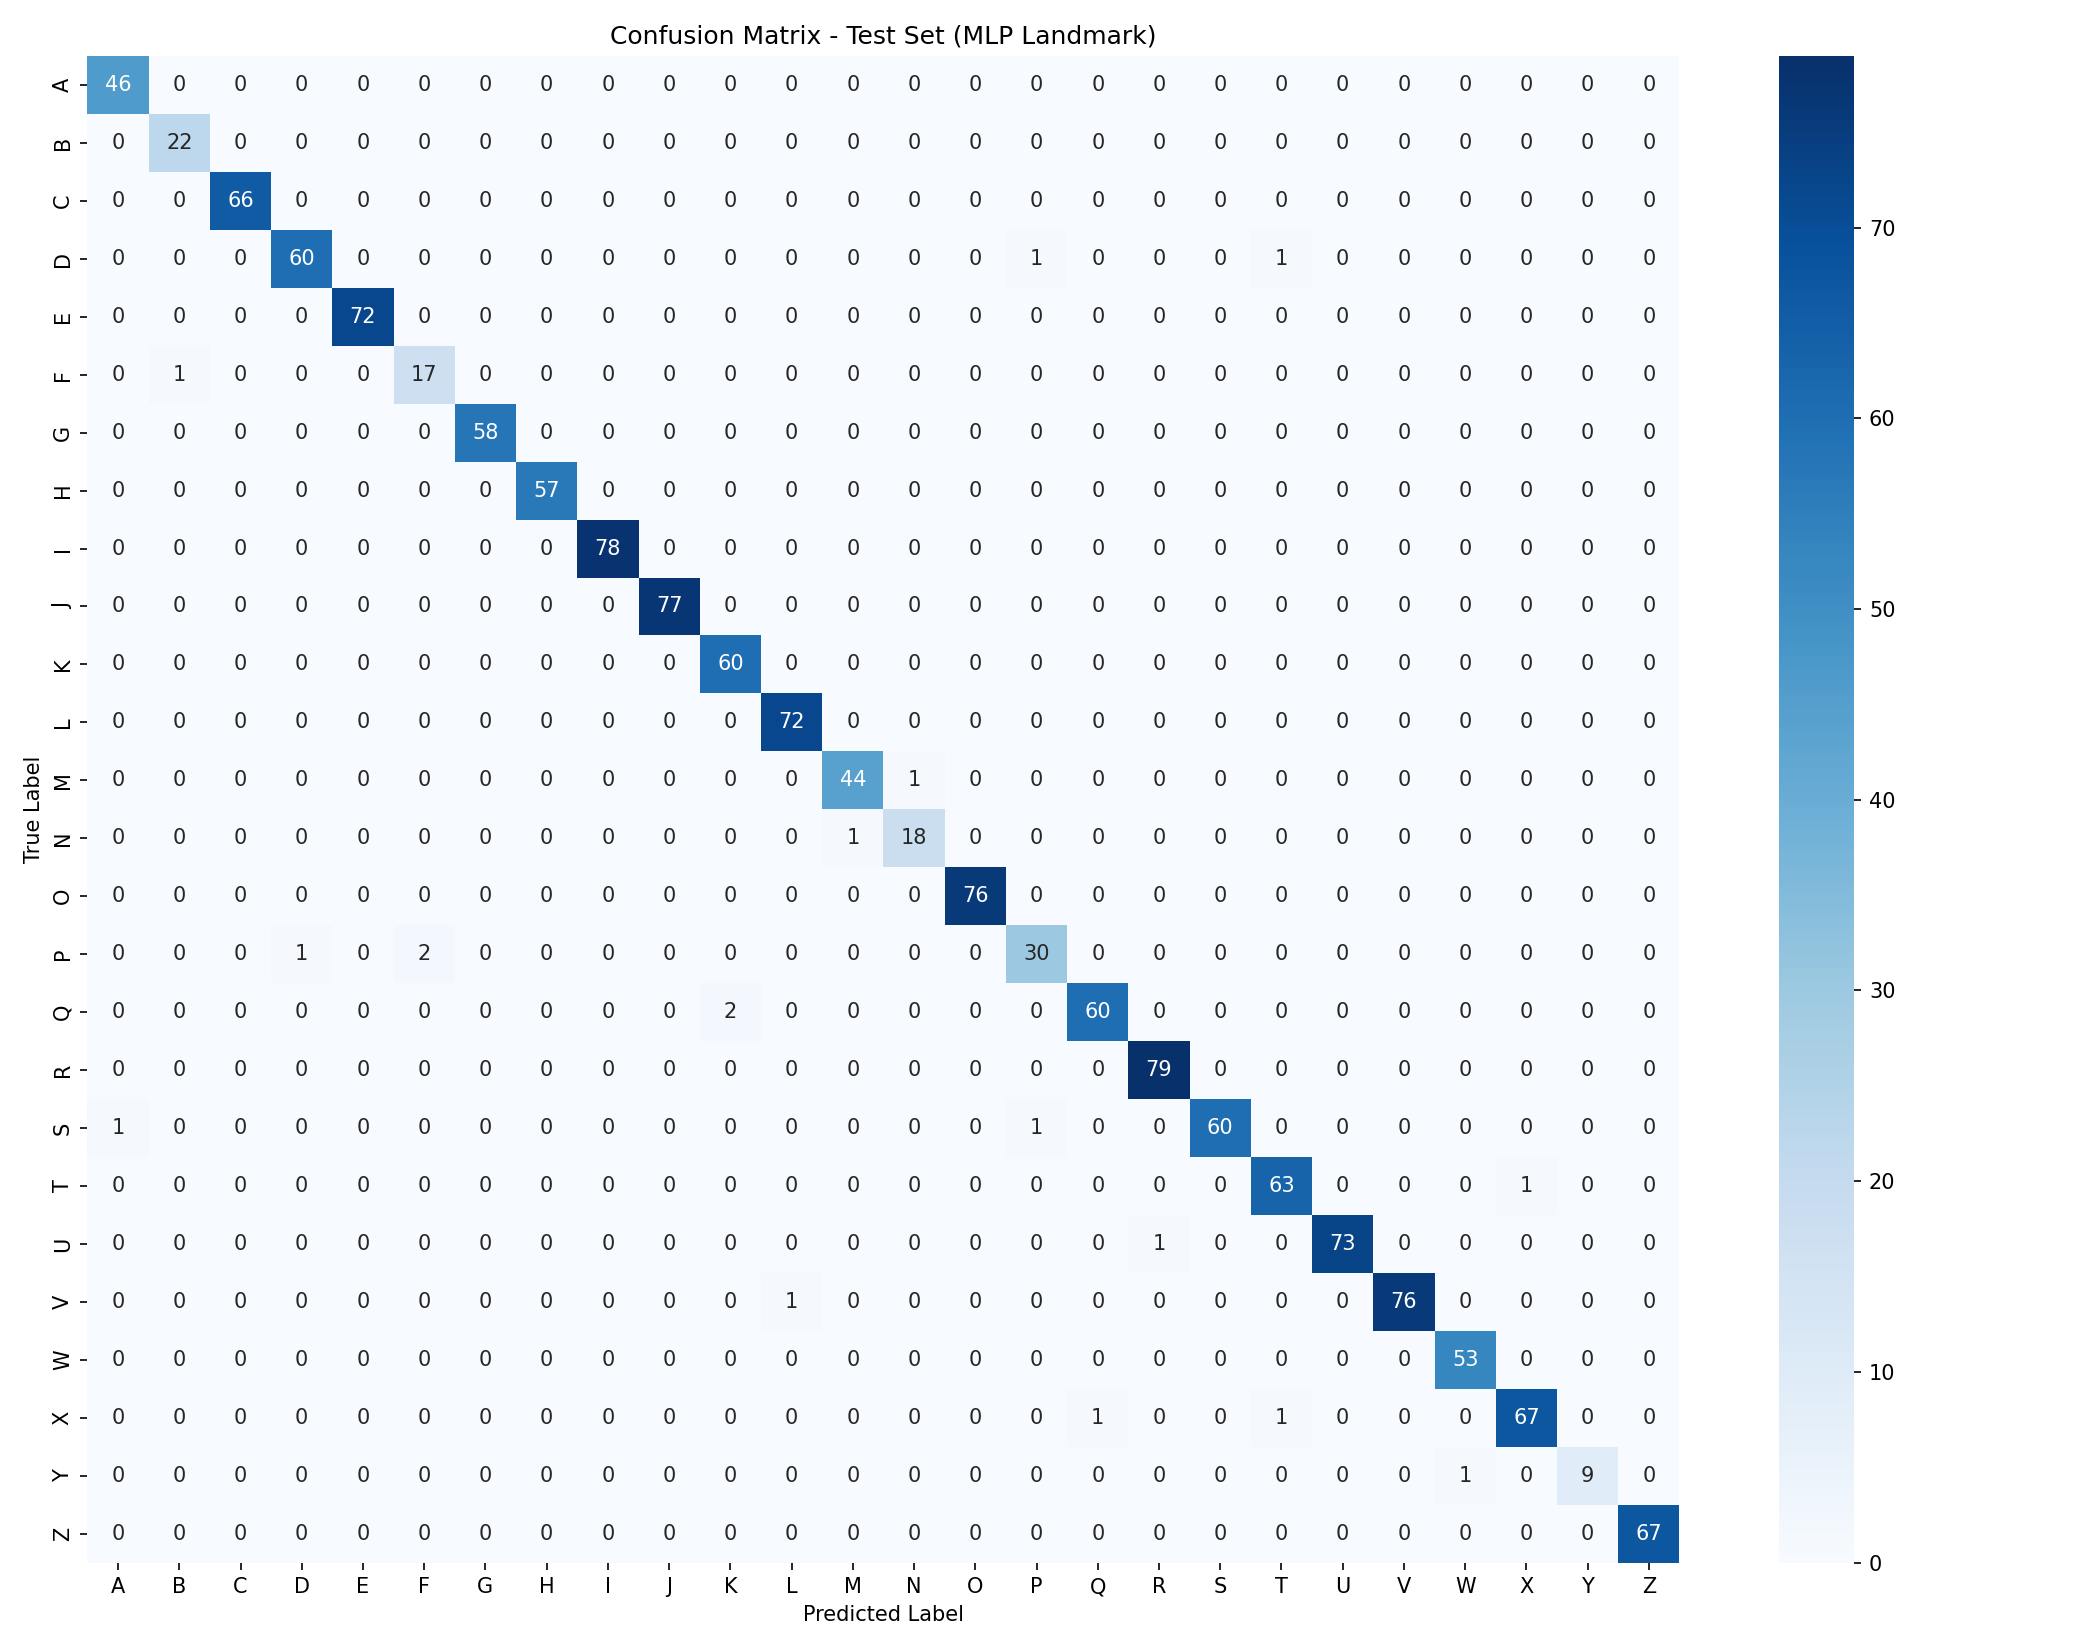

In [14]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from IPython.display import Image, display

# 1. Evaluasi Akurasi & Loss pada Test Set
test_loss, test_acc = model_mlp.evaluate(X_test, y_test, verbose=0)
print("=" * 50)
print(f"Test Accuracy MLP Landmark: {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Test Loss MLP Landmark    : {test_loss:.4f}")
print("=" * 50)

# 2. Cetak Classification Report
y_pred_probs = model_mlp.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_, digits=4))

# 3. Gambar & Tampilkan Grafik Training History (Accuracy & Loss)
if 'history' in locals():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Accuracy
    axes[0].plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
    axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
    axes[0].set_title('Grafik Akurasi Model MLP Landmark')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot Loss
    axes[1].plot(history.history['loss'], label='Train Loss', linewidth=2)
    axes[1].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
    axes[1].set_title('Grafik Loss Model MLP Landmark')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('grafik_training_mlp.png', dpi=150)
    plt.close(fig)
    display(Image(filename='grafik_training_mlp.png'))

# 4. Gambar & Tampilkan Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
fig_cm = plt.figure(figsize=(14, 11))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=le.classes_, yticklabels=le.classes_
)
plt.title('Confusion Matrix - Test Set (MLP Landmark)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('confusion_matrix_mlp.png', dpi=150)
plt.close(fig_cm)

# Paksa tampilkan gambar di output Colab
display(Image(filename='confusion_matrix_mlp.png'))

In [13]:
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
import gradio as gr
from collections import deque, Counter
import tensorflow as tf

# 1. Muat model dan daftar label huruf
if 'model_mlp' not in locals():
    model_mlp = tf.keras.models.load_model('bisindo_mlp_landmark.keras')

if 'le' in locals():
    daftar_label = [str(c).upper() for c in le.classes_]
elif 'labels' in locals():
    daftar_label = [str(c).upper() for c in np.unique(labels)]
else:
    y_raw = np.load('y_labels_clean.npy')
    daftar_label = [str(c).upper() for c in np.unique(y_raw)]

# 2. Pembagian Kategori Huruf BISINDO (1 Tangan vs 2 Tangan)
HURUF_1_TANGAN = {'C', 'E', 'I', 'J', 'L', 'O', 'R', 'U', 'V', 'Z'}
HURUF_2_TANGAN = {'A', 'B', 'D', 'F', 'G', 'H', 'K', 'M', 'N', 'P', 'Q', 'S', 'T', 'W', 'X', 'Y'}
# Buat mask (penyaring otomatis) sesuai urutan indeks label di model
mask_1_tangan = np.array([1.0 if h in HURUF_1_TANGAN else 0.0 for h in daftar_label], dtype=np.float32)
mask_2_tangan = np.array([1.0 if h in HURUF_2_TANGAN else 0.0 for h in daftar_label], dtype=np.float32)

# 3. Siapkan MediaPipe Hand Landmarker
base_options = python.BaseOptions(model_asset_path='hand_landmarker.task')
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    num_hands=2,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5
)
detector = vision.HandLandmarker.create_from_options(options)

HAND_CONNECTIONS = [
    (0,1),(1,2),(2,3),(3,4),
    (0,5),(5,6),(6,7),(7,8),
    (5,9),(9,10),(10,11),(11,12),
    (9,13),(13,14),(14,15),(15,16),
    (13,17),(17,18),(18,19),(19,20),(0,17)
]

riwayat_prediksi = deque(maxlen=7)
jumlah_tangan_sebelumnya = 0

# 4. Fungsi Prediksi dengan Pengunci Jumlah Tangan (Hand-Count Gate)
def prediksi_bisindo(frame, balik_cermin=True):
    global jumlah_tangan_sebelumnya

    if frame is None:
        return None, "Kamera belum aktif"

    if balik_cermin:
        frame = cv2.flip(frame, 1)

    annotated_img = frame.copy()
    h, w, _ = annotated_img.shape

    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
    result = detector.detect(mp_image)

    if not result.hand_landmarks:
        riwayat_prediksi.clear()
        jumlah_tangan_sebelumnya = 0
        return annotated_img, "Tangan tidak terdeteksi"

    # Hitung berapa tangan yang terdeteksi di kamera (1 atau 2)
    jumlah_tangan = min(len(result.hand_landmarks), 2)

    # Reset antrean smoothing jika pengguna berganti dari 1 tangan ke 2 tangan (atau sebaliknya)
    if jumlah_tangan != jumlah_tangan_sebelumnya:
        riwayat_prediksi.clear()
        jumlah_tangan_sebelumnya = jumlah_tangan

    fitur_126 = np.zeros(126, dtype=np.float32)

    for idx_tangan, hand_lms in enumerate(result.hand_landmarks[:2]):
        pts = [(int(lm.x * w), int(lm.y * h)) for lm in hand_lms]
        for s, e in HAND_CONNECTIONS:
            cv2.line(annotated_img, pts[s], pts[e], (0, 255, 0), 2)
        for pt in pts:
            cv2.circle(annotated_img, pt, 4, (255, 0, 0), -1)

        wrist_x, wrist_y, wrist_z = hand_lms[0].x, hand_lms[0].y, hand_lms[0].z
        koordinat_tangan = []
        for lm in hand_lms:
            koordinat_tangan.extend([lm.x - wrist_x, lm.y - wrist_y, lm.z - wrist_z])

        start_idx = idx_tangan * 63
        fitur_126[start_idx:start_idx + 63] = koordinat_tangan

    # Prediksi mentah dari model MLP
    input_data = np.expand_dims(fitur_126, axis=0)
    preds = model_mlp.predict(input_data, verbose=0)[0]

    # --- PENGUNCI JUMLAH TANGAN (HAND-COUNT FILTER) ---
    if jumlah_tangan == 1:
        preds = preds * mask_1_tangan  # Matikan semua huruf 2 tangan (seperti G, M, N, D)
    else:
        preds = preds * mask_2_tangan  # Matikan semua huruf 1 tangan (seperti C, I, J, R, U)

    # Normalisasi ulang persentase keyakinan di dalam kategori tangan yang aktif
    total_prob = np.sum(preds)
    if total_prob > 0:
        preds = preds / total_prob

    confidence = float(np.max(preds))
    idx_terbaik = int(np.argmax(preds))
    huruf_tebakan = daftar_label[idx_terbaik]

    if confidence >= 0.55:
        riwayat_prediksi.append(huruf_tebakan)

    if len(riwayat_prediksi) > 0:
        huruf_stabil = Counter(riwayat_prediksi).most_common(1)[0][0]
        status_teks = f"[{jumlah_tangan} Tangan] Huruf: {huruf_stabil} ({confidence*100:.1f}%)"
    else:
        status_teks = f"[{jumlah_tangan} Tangan] Kurang Yakin ({huruf_tebakan}: {confidence*100:.1f}%)"

    cv2.putText(annotated_img, status_teks, (15, 35),
                cv2.FONT_HERSHEY_SIMPLEX, 0.75, (0, 255, 0), 2)

    return annotated_img, status_teks

# 5. Jalankan Antarmuka Gradio Live
demo = gr.Interface(
    fn=prediksi_bisindo,
    inputs=[
        gr.Image(sources=["webcam"], streaming=True, label="Kamera Live Real-Time"),
        gr.Checkbox(value=True, label="Balik Efek Cermin Webcam")
    ],
    outputs=[
        gr.Image(label="Visualisasi Kerangka Tangan"),
        gr.Textbox(label="Hasil Prediksi Stabil")
    ],
    live=True,
    title="SignQuest BISINDO - Smart Hand-Count Filter (1 vs 2 Tangan)"
)

demo.launch(debug=False)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b23cae152dfe0f32f9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [15]:
import json, zipfile, os
import tensorflow as tf
from google.colab import files

# Konversi ke TFLite (Quantized) untuk Flutter
converter = tf.lite.TFLiteConverter.from_keras_model(model_mlp)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
with open('bisindo_mlp_landmark_quant.tflite', 'wb') as f:
    f.write(converter.convert())

# Simpan label & aturan 1 vs 2 tangan
daftar_kelas = [str(c).upper() for c in le.classes_]
with open('labels.txt', 'w') as f:
    f.write('\n'.join(daftar_kelas))

with open('labels_and_rules.json', 'w') as f:
    json.dump({
        "labels": daftar_kelas,
        "huruf_1_tangan": ["C", "E", "I", "J", "L", "O", "R", "U", "V", "Z"],
        "huruf_2_tangan": ["A", "B", "D", "F", "G", "H", "K", "M", "N", "P", "Q", "S", "T", "W", "X", "Y"],
        "confidence_threshold": 0.55,
        "smoothing_window": 7
    }, f, indent=2)

# Bungkus semua file model dan grafik ke dalam 1 ZIP
daftar_file = [
    'bisindo_mlp_landmark.keras',
    'bisindo_mlp_landmark_quant.tflite',
    'labels.txt',
    'labels_and_rules.json',
    'grafik_training_mlp.png',
    'confusion_matrix_mlp.png'
]

with zipfile.ZipFile('signquest_ml_artifacts.zip', 'w') as zf:
    for item in daftar_file:
        if os.path.exists(item):
            zf.write(item)

files.download('signquest_ml_artifacts.zip')

Saved artifact at '/tmp/tmpudw9eyi3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 126), dtype=tf.float32, name='keras_tensor_11')
Output Type:
  TensorSpec(shape=(None, 26), dtype=tf.float32, name=None)
Captures:
  133211488540752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488542672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488542096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488542480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488540944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488542288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488543248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488544208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488544400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488544592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133211488541520: T

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>